### Задание 3.3 Torch: Персептроны


In [10]:
!pip install torch torchvision torchaudio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 19.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.9/679.9 kB 3.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchvision] [torchvision]

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [13]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [15]:
torch.manual_seed(42)
np.random.seed(42)

In [16]:
transform = transforms.Compose([
    transforms.ToTensor()  # переводит изображение в тензор и масштабирует пиксели
])

In [17]:
full_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:05<00:00, 1.85MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 257kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 908kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.34MB/s]


In [18]:
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [19]:
len(full_train_dataset)

60000

In [20]:
len(test_dataset)

10000

In [21]:
train_size = 55000
val_size = 5000


In [22]:
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

In [23]:
batch_size = 64

In [24]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [25]:
class_names = [str(i) for i in range(10)]

In [26]:
def show_samples(dataset, n=16):
    plt.figure(figsize=(8, 8))
    for i in range(n):
        img, label = dataset[i]
        img = img.squeeze(0)  # убираем размерность канала
        plt.subplot(int(np.sqrt(n)), int(np.sqrt(n)), i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(f"Класс: {label}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

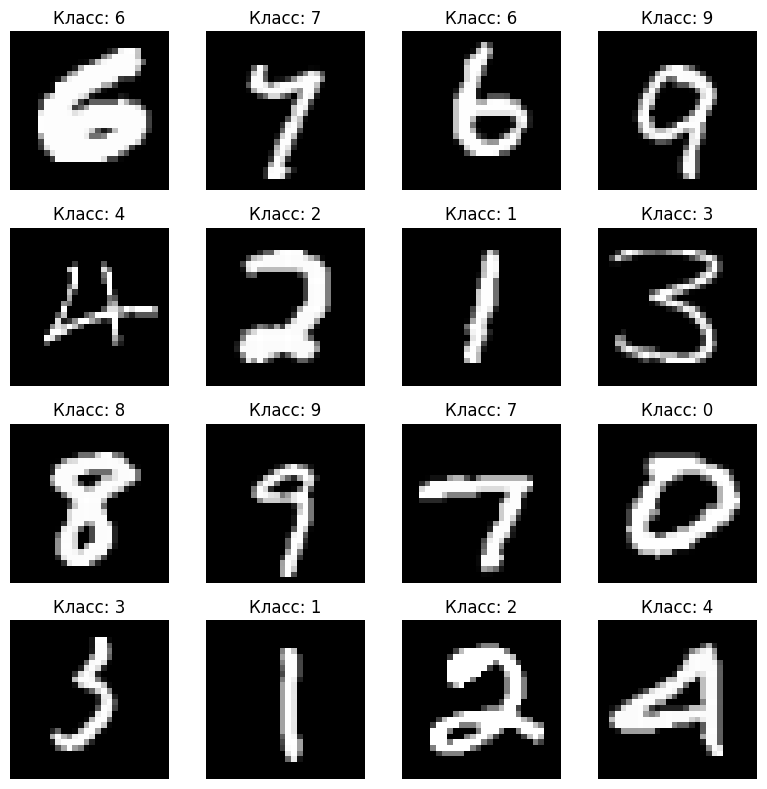

In [27]:
show_samples(train_dataset, n=16)

In [28]:
def get_labels_from_subset(subset):
    labels = []
    for _, label in subset:
        labels.append(label)
    return np.array(labels)


In [29]:
train_labels = get_labels_from_subset(train_dataset)
val_labels = get_labels_from_subset(val_dataset)
test_labels = np.array(test_dataset.targets)

/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_2853/2152939313.py:3: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  test_labels = np.array(test_dataset.targets)


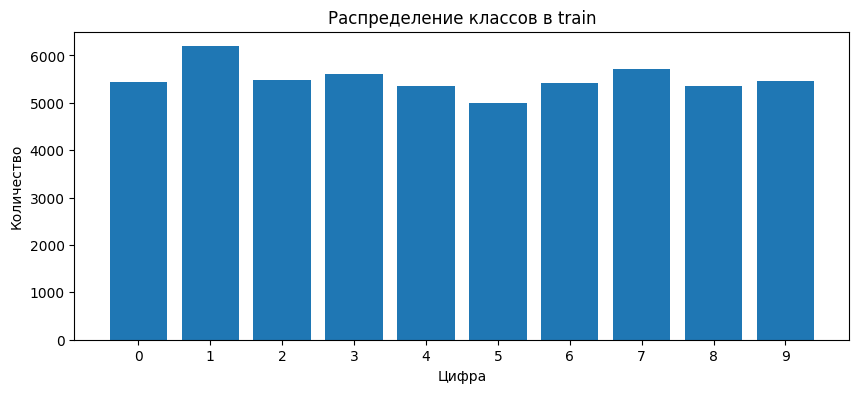

In [30]:

plt.figure(figsize=(10, 4))
plt.hist(train_labels, bins=np.arange(11) - 0.5, rwidth=0.8)
plt.xticks(range(10))
plt.title("Распределение классов в train")
plt.xlabel("Цифра")
plt.ylabel("Количество")
plt.show()

### Модель 1

простая нейронная сеть

In [32]:
class MLP1(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

### Модель 2

больше слоёв + Dropout для борьбы с переобучением

In [33]:
class MLP2(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.Tanh(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

### Модель 3

глубокая сеть с нормализацией и современной активацией

In [34]:
class MLP3(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.GELU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

### Обучение

точность модели

In [35]:
def accuracy_from_logits(logits, y_true):
    preds = torch.argmax(logits, dim=1)
    return (preds == y_true).float().mean().item()

обучает модель одну эпоху: прямой проход, подсчёт loss, backward, обновление весов. Возвращает средний loss и accuracy по всей обучающей выборке.

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    total_acc = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device) #перенос на устройство:

        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        total_acc += (torch.argmax(logits, dim=1) == y).sum().item()

    epoch_loss = total_loss / len(loader.dataset)
    epoch_acc = total_acc / len(loader.dataset)
    return epoch_loss, epoch_acc

оценивает модель на валидационной или тестовой 
@torch.no_grad() — отключает вычисление градиентов      
model.eval() — переводит модель в режим оценки (отключает Dropout, фиксирует BatchNorm)     

В цикле по батчам:      
Перенос данных на устройство        
Прямой проход logits = model(x)       
Подсчёт loss и accuracy         
Сбор всех предсказаний и истинных меток     

В конце:        
Вычисляет средний loss и accuracy по всей выборке       
Объединяет предсказания через torch.cat()       

In [37]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    total_acc = 0
    all_preds = []
    all_true = []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        total_acc += (torch.argmax(logits, dim=1) == y).sum().item()

        all_preds.append(torch.argmax(logits, dim=1).cpu())
        all_true.append(y.cpu())

    epoch_loss = total_loss / len(loader.dataset)
    epoch_acc = total_acc / len(loader.dataset)

    all_preds = torch.cat(all_preds).numpy()
    all_true = torch.cat(all_true).numpy()

    return epoch_loss, epoch_acc, all_true, all_preds

полностью обучает модель и сохраняет лучшую версию по валидации
Переносит модель на устройство и создаёт CrossEntropyLoss       
Инициализирует оптимизатор:     
SGD (с momentum=0.9)        
Adam        
AdamW       

Запускает цикл обучения на epochs эпох:     
Обучение: train_one_epoch       
Валидация: evaluate     
Сохраняет метрики в history     

Сохраняет веса лучшей модели по val_acc     
В конце загружает лучшие веса обратно в модель      

In [ ]:
def run_experiment(model, optimizer_name, lr=1e-3, epochs=10):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif optimizer_name == "Adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    elif optimizer_name == "AdamW":
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    else:
        raise ValueError("Неизвестный оптимизатор")

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_acc = 0
    best_state = None

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(
            f"Epoch {epoch:02d} | "
            f"train loss={train_loss:.4f}, train acc={train_acc:.4f} | "
            f"val loss={val_loss:.4f}, val acc={val_acc:.4f}"
        )

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history

Для каждой модели:      
Обучение через run_experiment           
Сохранение истории обучения     
Оценка на тестовой выборке (evaluate)           
Сбор результатов в таблицу      

In [39]:
experiments = [
    ("MLP1", MLP1(), "SGD", 0.05),
    ("MLP2", MLP2(), "Adam", 0.001),
    ("MLP3", MLP3(), "AdamW", 0.001),
]

results = []
histories = {}
trained_models = {}

for name, model, optim_name, lr in experiments:
    print(f"\n Обучение {name} | {optim_name} | lr={lr}")
    trained_model, history = run_experiment(model, optim_name, lr=lr, epochs=10)
    histories[name] = history
    trained_models[name] = trained_model

    criterion = nn.CrossEntropyLoss()
    test_loss, test_acc, y_true, y_pred = evaluate(trained_model, test_loader, criterion, device)

    results.append({
        "model": name,
        "optimizer": optim_name,
        "lr": lr,
        "test_loss": test_loss,
        "test_acc": test_acc
    })

results_df = pd.DataFrame(results)
results_df


===== Обучение MLP1 | SGD | lr=0.05 =====
Epoch 01 | train loss=0.2872, train acc=0.9161 | val loss=0.1477, val acc=0.9546
Epoch 02 | train loss=0.1146, train acc=0.9651 | val loss=0.1079, val acc=0.9664
Epoch 03 | train loss=0.0808, train acc=0.9752 | val loss=0.1130, val acc=0.9686
Epoch 04 | train loss=0.0619, train acc=0.9811 | val loss=0.0900, val acc=0.9748
Epoch 05 | train loss=0.0475, train acc=0.9852 | val loss=0.0850, val acc=0.9738
Epoch 06 | train loss=0.0379, train acc=0.9885 | val loss=0.0880, val acc=0.9758
Epoch 07 | train loss=0.0313, train acc=0.9904 | val loss=0.0840, val acc=0.9772
Epoch 08 | train loss=0.0251, train acc=0.9920 | val loss=0.0702, val acc=0.9788
Epoch 09 | train loss=0.0200, train acc=0.9941 | val loss=0.0690, val acc=0.9782
Epoch 10 | train loss=0.0157, train acc=0.9953 | val loss=0.0736, val acc=0.9778

===== Обучение MLP2 | Adam | lr=0.001 =====
Epoch 01 | train loss=0.3128, train acc=0.9075 | val loss=0.1812, val acc=0.9468
Epoch 02 | train loss

,model,optimizer,lr,test_loss,test_acc
0,MLP1,SGD,0.050,0.070503,0.9800
1,MLP2,Adam,0.001,0.079289,0.9755
2,MLP3,AdamW,0.001,0.053550,0.9843


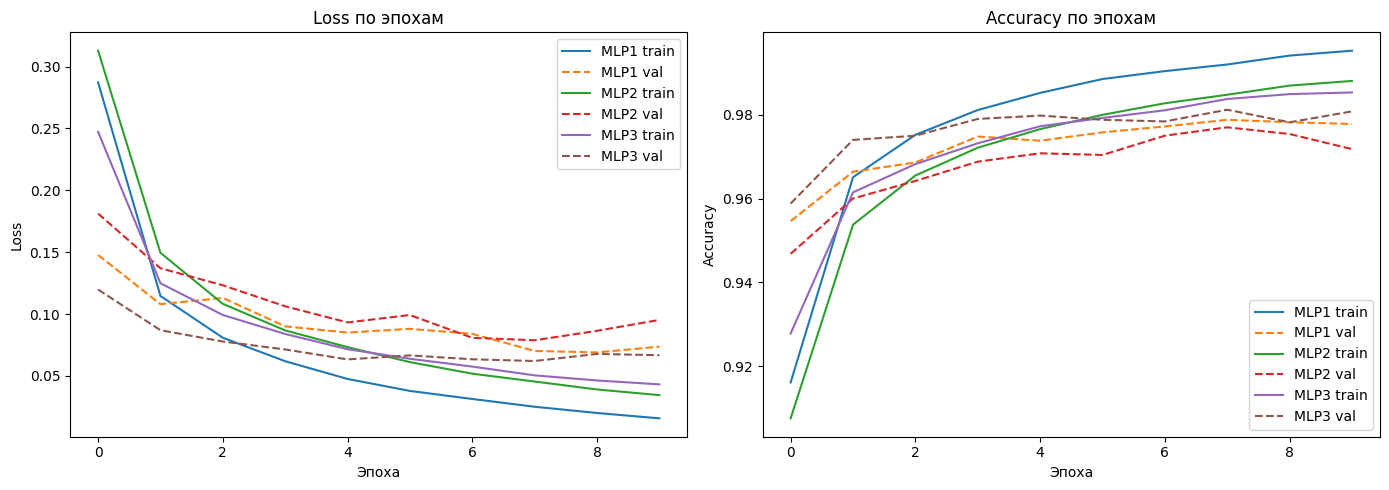

In [41]:
def plot_history(histories):
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    for name, h in histories.items():
        plt.plot(h["train_loss"], label=f"{name} train")
        plt.plot(h["val_loss"], linestyle="--", label=f"{name} val")
    plt.title("Loss по эпохам")
    plt.xlabel("Эпоха")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    for name, h in histories.items():
        plt.plot(h["train_acc"], label=f"{name} train")
        plt.plot(h["val_acc"], linestyle="--", label=f"{name} val")
    plt.title("Accuracy по эпохам")
    plt.xlabel("Эпоха")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(histories)

In [43]:
def plot_confusion(y_true, y_pred, title="Confusion matrix"):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(title)
    plt.xlabel("Предсказанный класс")
    plt.ylabel("Истинный класс")
    plt.show()

In [44]:
@torch.no_grad()
def collect_mistakes(model, loader, device, max_items=25):
    model.eval()
    mistakes = []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        preds = torch.argmax(logits, dim=1)

        wrong = preds != y
        if wrong.any():
            x_wrong = x[wrong].cpu()
            y_wrong = y[wrong].cpu()
            p_wrong = preds[wrong].cpu()

            for img, true_label, pred_label in zip(x_wrong, y_wrong, p_wrong):
                mistakes.append((img, int(true_label), int(pred_label)))
                if len(mistakes) >= max_items:
                    return mistakes

    return mistakes

def show_mistakes(mistakes, title="Ошибки модели"):
    n = len(mistakes)
    if n == 0:
        print("Ошибок не найдено.")
        return

    cols = 5
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(15, 3 * rows))

    for i, (img, true_label, pred_label) in enumerate(mistakes):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img.squeeze(0), cmap="gray")
        plt.title(f"true={true_label}\npred={pred_label}")
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

In [45]:
best_model_name = results_df.sort_values("test_acc", ascending=False).iloc[0]["model"]
best_model = trained_models[best_model_name]

Лучшая модель: MLP3
Test accuracy: 0.9843
Test loss: 0.0536


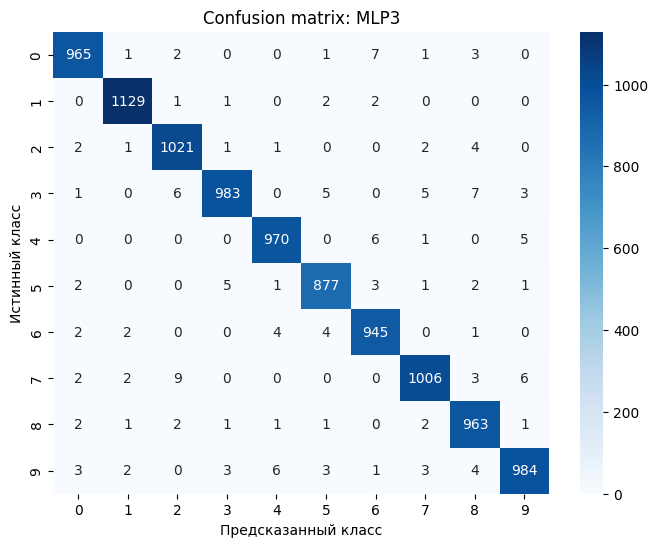

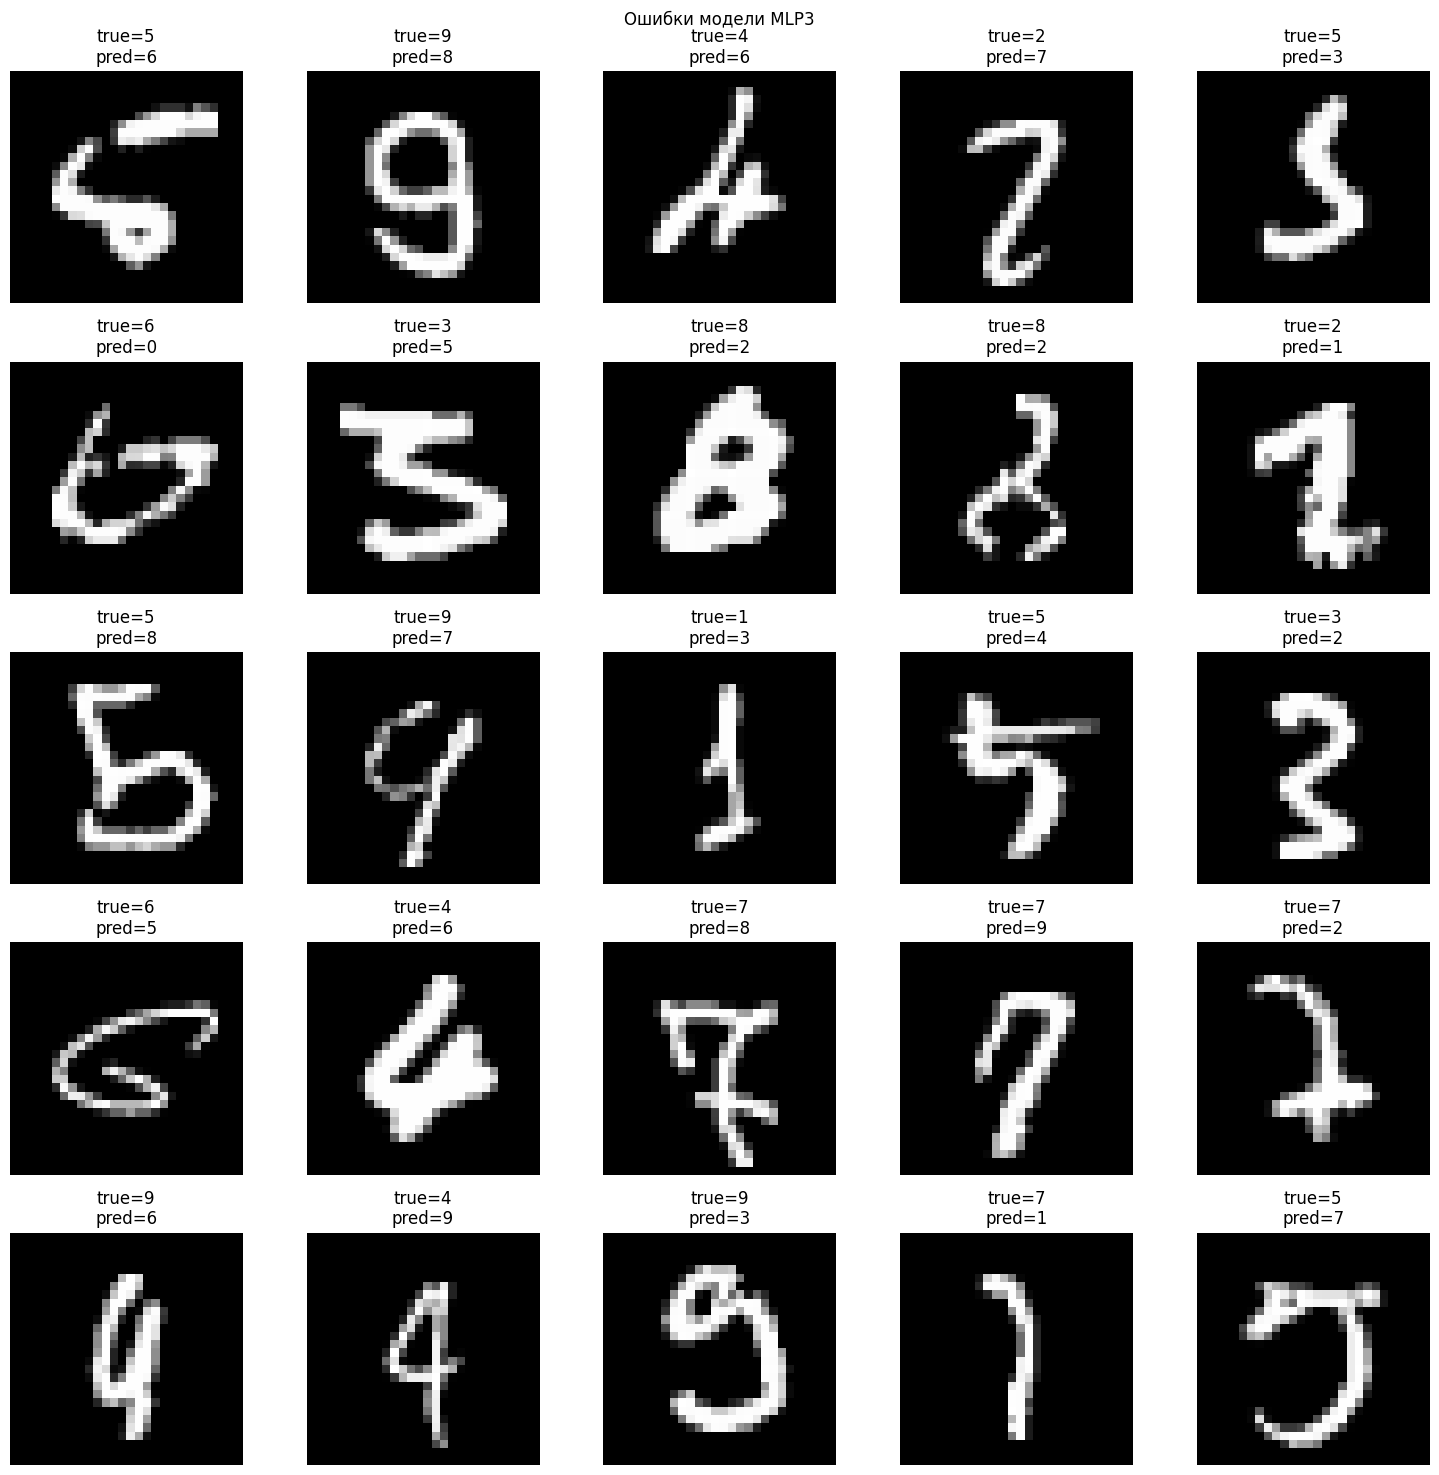

In [46]:
criterion = nn.CrossEntropyLoss()
test_loss, test_acc, y_true, y_pred = evaluate(best_model, test_loader, criterion, device)

print(f"Лучшая модель: {best_model_name}")
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

plot_confusion(y_true, y_pred, title=f"Confusion matrix: {best_model_name}")

mistakes = collect_mistakes(best_model, test_loader, device, max_items=25)
show_mistakes(mistakes, title=f"Ошибки модели {best_model_name}")

In [48]:
print(classification_report(y_true, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9857    0.9847    0.9852       980
           1     0.9921    0.9947    0.9934      1135
           2     0.9808    0.9893    0.9850      1032
           3     0.9889    0.9733    0.9810      1010
           4     0.9868    0.9878    0.9873       982
           5     0.9821    0.9832    0.9826       892
           6     0.9803    0.9864    0.9834       958
           7     0.9853    0.9786    0.9819      1028
           8     0.9757    0.9887    0.9822       974
           9     0.9840    0.9752    0.9796      1009

    accuracy                         0.9843     10000
   macro avg     0.9842    0.9842    0.9842     10000
weighted avg     0.9843    0.9843    0.9843     10000

